# Phytoplankton -- binary model analysis

Same analysis as `runs/hiernet_mnr.ipynb`, for the *phytoplankton vs not
phytoplankton* task: build the eval loader, inspect the augmentation pipeline,
(re)train, score checkpoints, and visualise training curves / confusion / a
confidence cascade / attention + Grad-CAM.

Two structural differences from the MNR notebook:

- **One eval target.** There is no messy-background set for phytoplankton, so
  everything runs on the held-out **test split** only (`hiernet_mnr.ipynb` also
  runs a `Messy_background` target).
- **One hierarchy level, two leaves.** "per-level" plots and the cascade collapse
  to Level 1; Grad-CAM `weights` are length 1.

In [2]:
import sys
from pathlib import Path

import torch
from dotenv import load_dotenv

# repo root = nearest ancestor containing hierroute/  (works from notebooks/, phytoplankton/, or root)
project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hierroute").is_dir())
for _p in (project_root, project_root / "phytoplankton" / "scripts", project_root / "runs" / "scripts"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
load_dotenv(project_root / ".env")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("project_root:", project_root)
print("device:", device)

project_root: /home/tjhinale/repo/Zooplankton_Classification
device: cuda


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms

from hierroute import HierRouteNet, Trainer, Visualize, visualize_swin_attention
from hierroute.extra_functions import visualize_gradcam, RandomBackgroundNoise

# phytoplankton dataset / dataloader builders  (phytoplankton/scripts/data_setup.py)
from data_setup import build_dataloaders, train_val_test_split, EVAL_TRANSFORMS, RESOLUTION, SEED
import constants as C

# shared, hierarchy-agnostic eval + confidence-cascade helpers  (runs/scripts/hiernet_eval.py)
from hiernet_eval import evaluate_checkpoint, per_class_outcomes, plot_outcome_stacked_bar

# Data

The held-out **test split** of the phytoplankton binary dataset, built through
`phytoplankton/scripts/data_setup.py` so the construction matches
`train_swin_cnn_phyto.py` and is seeded (same `0.7 / 0.1 / 0.2` split).

`build_dataloaders(train_transforms=EVAL_TRANSFORMS)` gives every split a clean
`Resize + ToTensor` pipeline -- no flips / noise -- so the metrics below are an
honest held-out number, not the augmented in-training test split that
`train_swin_cnn_phyto.py` writes to each checkpoint's own `eval_results.json`.

`constants.BINARY_CLASS_FOLDERS` pools the raw FlowCam class folders into the two
model classes; `constants.IGNORED_CLASSES` (the `Duplicate*` and TBD folders) are
left out entirely.

In [4]:
test_hier_dataset, _, _, test_loader = build_dataloaders(
    train_transforms=EVAL_TRANSFORMS, balanced=False, print_details=True,
)
train_split, val_split, test_split = train_val_test_split(test_hier_dataset)
id_to_name = {v: k for k, v in test_hier_dataset.label_to_ids.items()}
print(f"\ntest split: {len(test_split)} samples | label_to_ids: {test_hier_dataset.label_to_ids}")

[leaves_only] Kept 9254 samples | Removed 0 non-leaf samples

Total Dataset: Size = 9254 | Levels = 1
all_node_counts: {0: 9254, 1: 3864, 2: 5390}

nodes_by_level: {0: [0], 1: [1, 2]}


------------------------Level 0------------------------
Level: 0 | Class Name: root                 | Class Label:   0 | Type: Parent | Count:   9254 | Prop: 1.00

------------------------Level 1------------------------
Level: 1 | Class Name: Not Phytoplankton    | Class Label:   1 | Type: Leaf   | Count:   3864 | Prop: 0.42
Level: 1 | Class Name: Phytoplankton        | Class Label:   2 | Type: Leaf   | Count:   5390 | Prop: 0.58

test split: 1851 samples | label_to_ids: {'root': 0, 'Not Phytoplankton': 1, 'Phytoplankton': 2}


# Visualize

What the model actually sees. Top row is the raw grayscale crop at native
resolution; middle row is the training pipeline (`train_swin_cnn_phyto.py` with
`PHYTO_NOISE_AUG=0`); bottom row adds `RandomBackgroundNoise` (`PHYTO_NOISE_AUG=1`).

Unlike `hiernet_mnr.ipynb`, the phyto pipeline has no `RandomRotation` / `Pad`, so
there is no black-frame mismatch between train and eval -- flips are the only
geometric augmentation and they are label-preserving.

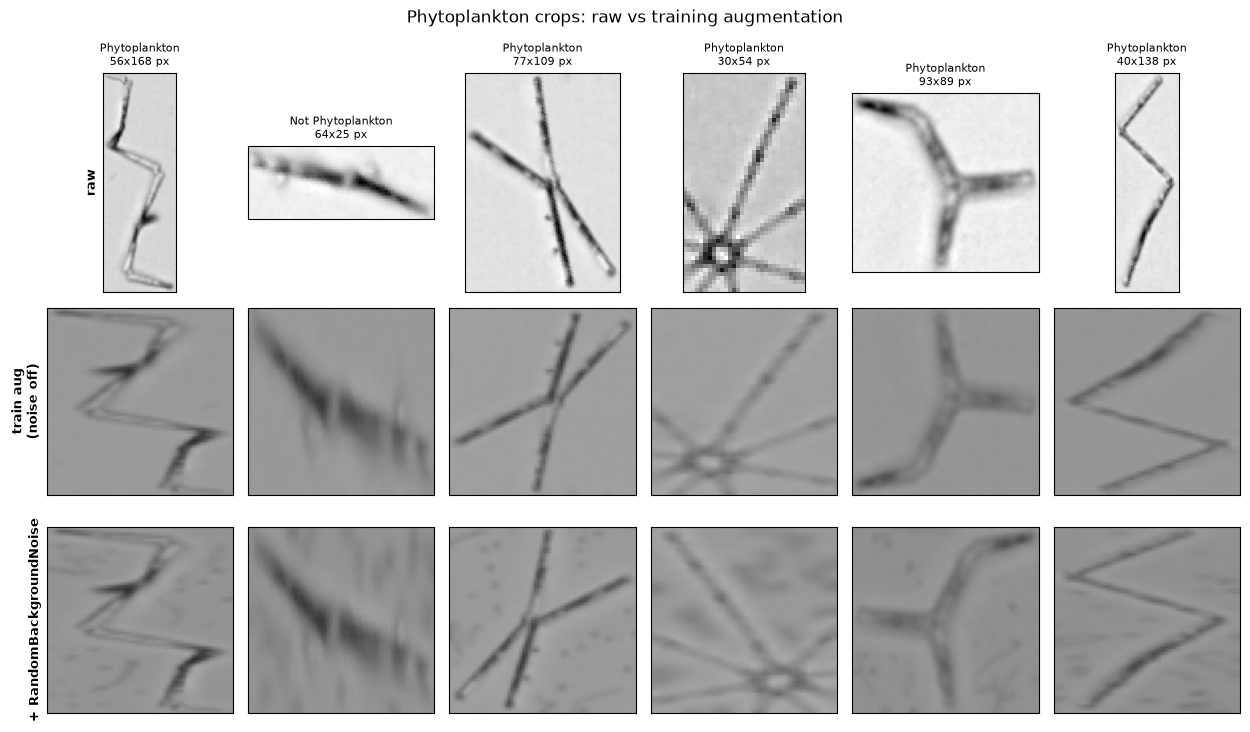

In [5]:
import random
from PIL import Image

N_SHOW = 6
rng = random.Random(0)
picks = rng.sample(list(test_split), N_SHOW)

_geo = [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
        transforms.Resize((RESOLUTION, RESOLUTION)), transforms.ToTensor()]
train_tf = transforms.Compose(_geo)
noise_tf = transforms.Compose([RandomBackgroundNoise(p=1.0), *_geo])

rows = [("raw", None), ("train aug\n(noise off)", train_tf), ("+ RandomBackgroundNoise", noise_tf)]

# the transforms draw from the global torch/random streams -- snapshot & restore
_torch_state, _py_state = torch.get_rng_state(), random.getstate()

fig, axes = plt.subplots(len(rows), N_SHOW, figsize=(2.1 * N_SHOW, 2.5 * len(rows)))
for c, idx in enumerate(picks):
    img = Image.open(test_hier_dataset.image_paths[idx]).convert("L")
    for r, (label, tf) in enumerate(rows):
        ax = axes[r][c]
        ax.set_xticks([]); ax.set_yticks([])
        if tf is None:
            ax.imshow(img, cmap="gray")
            ax.set_title(f"{id_to_name[test_hier_dataset.labels[idx]]}\n{img.size[0]}x{img.size[1]} px", fontsize=8)
        else:
            ax.imshow(tf(img)[0].numpy(), cmap="gray", vmin=0, vmax=1)
        if c == 0:
            ax.set_ylabel(label, fontsize=9, fontweight="bold")

torch.set_rng_state(_torch_state)
random.setstate(_py_state)
fig.suptitle("Phytoplankton crops: raw vs training augmentation", fontsize=12)
plt.tight_layout()
plt.show()

# Training

Two `HierRouteNet(backbone="swin_t", expert_type="cnn")` models, differing only in
whether `RandomBackgroundNoise` (synthetic dirt) is applied during training --
mirrors `train_swin_cnn_phyto.py` (`PHYTO_NOISE_AUG`, default off).

`train_variant(...)` below is the notebook-native path; the CLI equivalents are
`phytoplankton/scripts/train_swin_cnn_phyto.py` and `launch_training.sh`. `Trainer`
appends `_1`, `_2`, ... rather than overwriting an existing `model_dir`, so
re-running is safe. Each run is ~15-25 min.

In [6]:
from datetime import date


def train_variant(add_noise: bool = False, epochs: int = 40, lr: float = 3e-4,
                  patience: int = 10, delta: float = 0.001) -> str:
    variant = "noise" if add_noise else "baseline"

    tfs = []
    if add_noise:
        # first, on the raw native-resolution crop -- add_synthetic_dirt's speck/fiber
        # sizes are calibrated at native resolution
        tfs.append(RandomBackgroundNoise(p=0.8))
    tfs += [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
            transforms.Resize((RESOLUTION, RESOLUTION)), transforms.ToTensor()]

    hier_dataset, train_loader, val_loader, _ = build_dataloaders(
        train_transforms=transforms.Compose(tfs), balanced=True, print_details=False,
    )
    model = HierRouteNet(
        hierarchy=hier_dataset.hierarchy, label_to_id=hier_dataset.label_to_ids,
        backbone="swin_t", expert_type="cnn", freeze_backbone=False,
    )
    model_dir = str(project_root / "training_result" / "phytoplankton"
                    / f"swin_t_cnn_{variant}_{date.today():%m-%d}")
    trainer = Trainer(learning_rate=lr, max_epochs=epochs, device=device,
                      print_every=1, model_dir=model_dir)
    trainer.fit(model, train_loader, val_loader, scheduler=True, patience=patience, delta=delta)
    return trainer.model_dir

In [7]:
# Uncomment to (re)train from scratch:
# baseline_dir = train_variant(add_noise=False)
# noise_dir    = train_variant(add_noise=True)

# Already-trained checkpoints (edit to match what's on disk):
baseline_dir = str(project_root / "training_result/phytoplankton/swin_t_cnn_baseline_08-29")
noise_dir    = str(project_root / "training_result/phytoplankton/swin_t_cnn_noise_08-29")

for name, d in [("baseline", baseline_dir), ("noise", noise_dir)]:
    print(f"{name:9s} {'OK  ' if Path(d, 'best_model.pt').exists() else 'MISSING'} {d}")

baseline  OK   /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29
noise     MISSING /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_noise_08-29


# Evaluation

Each checkpoint is loaded fresh against the binary hierarchy and scored on the
**clean** test loader via `evaluate_checkpoint` (`runs/scripts/hiernet_eval.py`).
Predictions/metrics are written to `{checkpoint_dir}_test_eval/` -- kept separate
from the checkpoint's own `eval_results.json` (which reflects
`train_swin_cnn_phyto.py`'s *augmented* in-training test split).

Missing checkpoints are skipped, so this runs with baseline only if the noise
model hasn't been trained.

In [8]:
CHECKPOINTS = {"baseline": baseline_dir, "noise": noise_dir}
TARGETS = {"test": (test_hier_dataset, test_loader)}

models, level_results = {}, {}
for ckpt_name, ckpt_dir in CHECKPOINTS.items():
    if not Path(ckpt_dir, "best_model.pt").exists():
        print(f"skip '{ckpt_name}' -- no checkpoint at {ckpt_dir}")
        continue
    for tag, (ds, loader) in TARGETS.items():
        print(f"\n===== {ckpt_name} / {tag} =====")
        models[ckpt_name, tag], level_results[ckpt_name, tag] = evaluate_checkpoint(
            ckpt_dir, ds, loader, device, tag=tag, backbone="swin_t", expert_type="cnn",
        )

trained = sorted({k for k, _ in level_results})
print("\nevaluated:", trained)


===== baseline / test =====


Loaded checkpoint: /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29/best_model.pt
Hierarchical Evaluation:
  Level 1: Acc=0.9265 | F1=0.9246 | Prec=0.9240 | Rec=0.9252 | n=1851
    Not Phytoplankton      Acc=0.9172 | F1=0.9125 | Prec=0.9078 | Rec=0.9172 | n=773
    Phytoplankton          Acc=0.9332 | F1=0.9367 | Prec=0.9402 | Rec=0.9332 | n=1078

Structural Consistency:
  PASSED — all 1851 predictions follow a valid path in the hierarchy

Saved to '/home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29_test_eval/'
  predictions.npz  — leaf predictions + per-level aligned arrays
  eval_results.json — level and mismatch results
skip 'noise' -- no checkpoint at /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_noise_08-29

evaluated: ['baseline']


# Visualize -- Baseline

`plot_train()` reads the checkpoint's own `training_info.json` (training curves).
`plot_pred` / `plot_level_comparison` / `plot_class_size_vs_accuracy` read
`{baseline_dir}_test_eval/`. With two classes the "per-level" plots are a single
Level-1 panel and the confusion matrix is 2x2.

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29/train_metrics.png


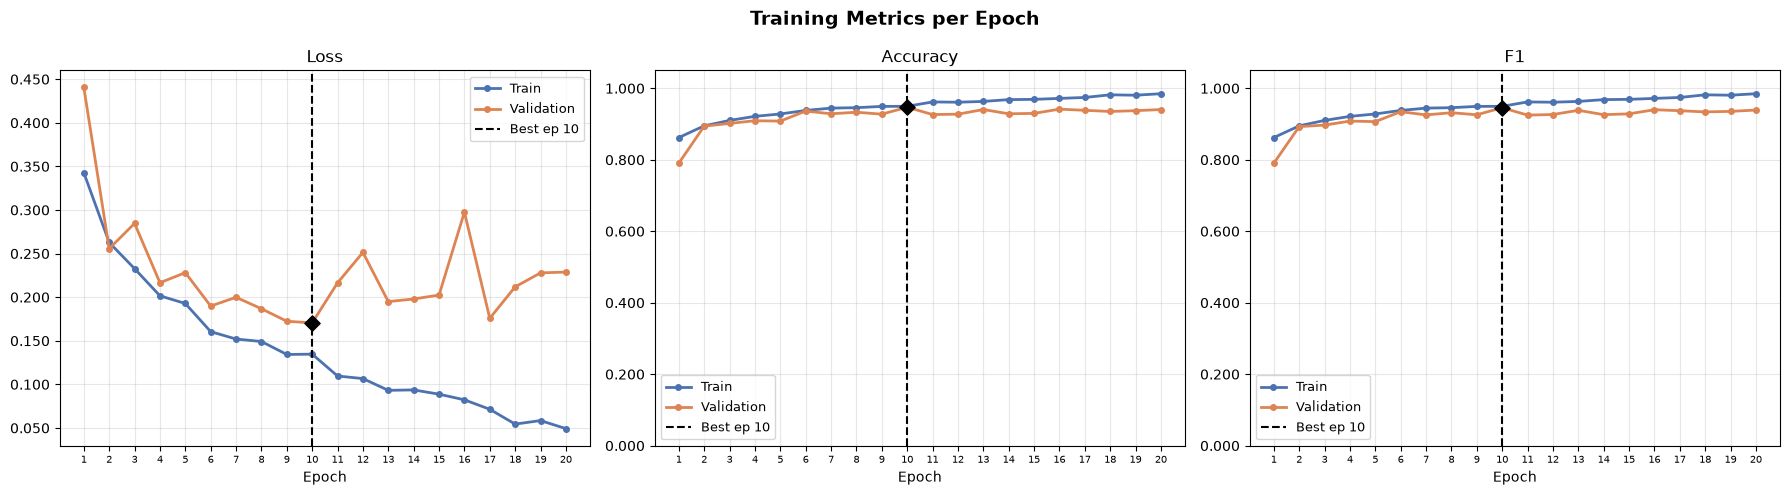

========== baseline / test ==========
  [Visualize] training_info.json not found in '/home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29_test_eval' — plot_train unavailable
Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29_test_eval/confusion_matrix_level1.png


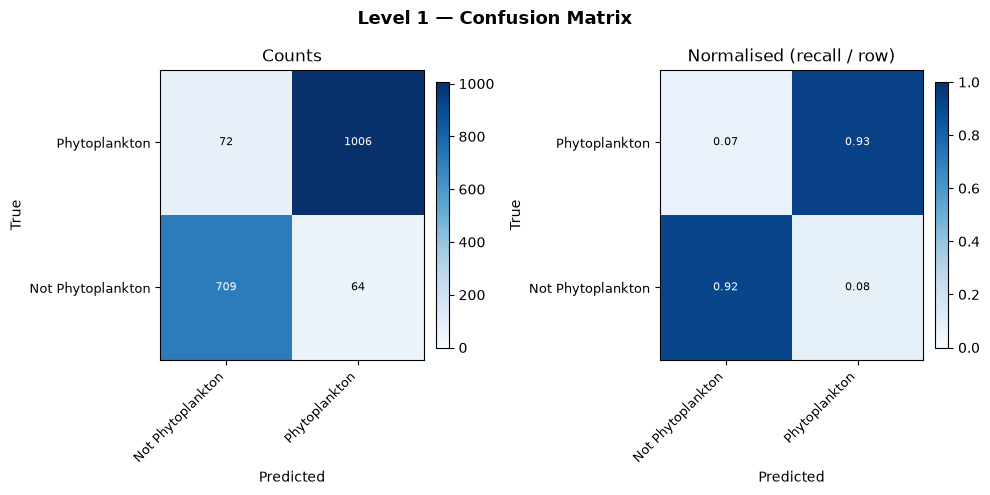

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29_test_eval/class_metrics_level1.png


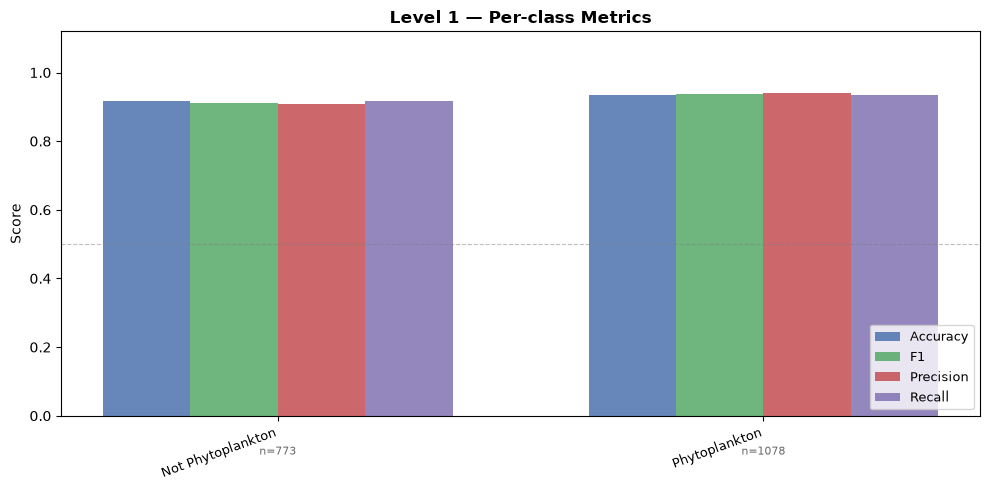

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29_test_eval/level_comparison.png


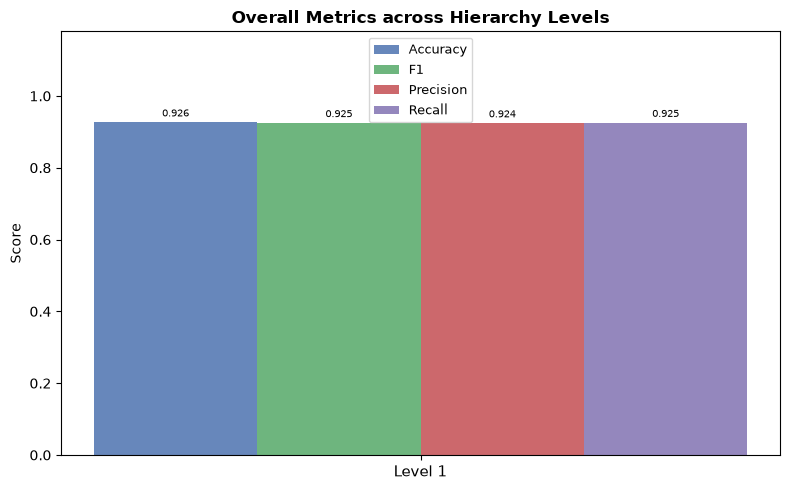

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29_test_eval/level_comparison.png


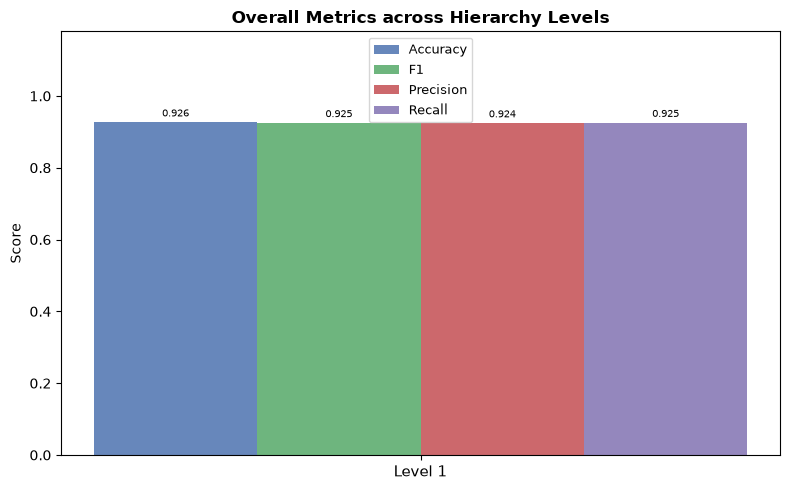

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/phytoplankton/swin_t_cnn_baseline_08-29_test_eval/size_vs_accuracy.png


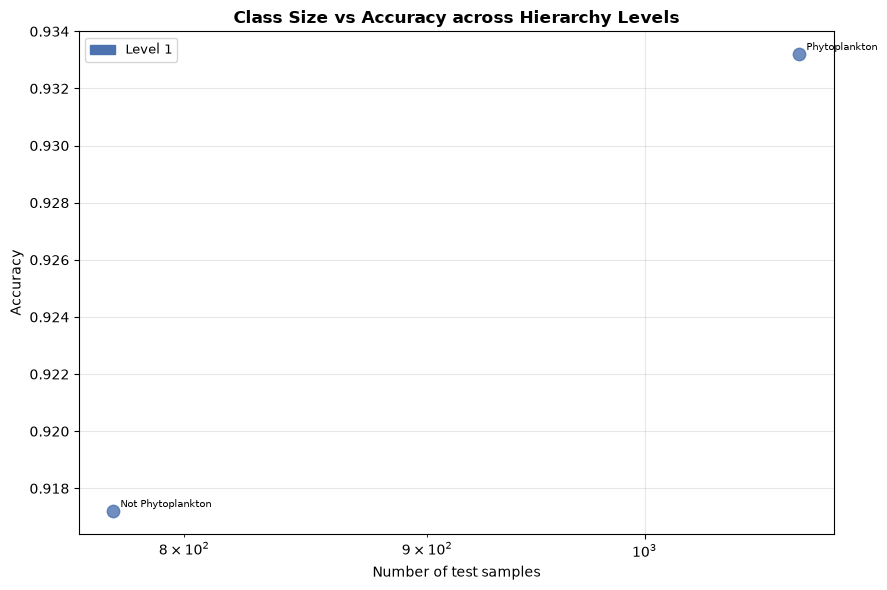

In [9]:
Visualize(baseline_dir).plot_train()

for tag in TARGETS:
    if ("baseline", tag) not in level_results:
        continue
    print(f"========== baseline / {tag} ==========")
    v = Visualize(f"{baseline_dir}_{tag}_eval")
    v.plot_pred()
    v.plot_level_comparison()
    v.plot_class_size_vs_accuracy()

# Visualize -- With background-noise augmentation

Only runs if a `noise` checkpoint exists (default training is baseline-only --
`PHYTO_NOISE_AUG` is off, since the synthetic-dirt augmentation was tuned on the
zooplankton dataset).

In [10]:
if ("noise", "test") in level_results:
    Visualize(noise_dir).plot_train()
    for tag in TARGETS:
        print(f"========== noise / {tag} ==========")
        v = Visualize(f"{noise_dir}_{tag}_eval")
        v.plot_pred()
        v.plot_level_comparison()
        v.plot_class_size_vs_accuracy()
else:
    print("no noise checkpoint -- run train_variant(add_noise=True) or "
          "PHYTO_NOISE_AUG=1 ./phytoplankton/scripts/launch_training.sh")

no noise checkpoint -- run train_variant(add_noise=True) or PHYTO_NOISE_AUG=1 ./phytoplankton/scripts/launch_training.sh


# Baseline vs. Noise: side-by-side comparison

Level-1 overall metrics, baseline vs. noise-augmented training. Falls back to a
one-model summary if only baseline has been trained.

In [11]:
metrics_to_plot = ["accuracy", "f1", "precision", "recall"]

for tag in TARGETS:
    have_b = ("baseline", tag) in level_results
    have_n = ("noise", tag) in level_results
    if not have_b and not have_n:
        continue
    levels = sorted(level_results["baseline" if have_b else "noise", tag])

    if have_b and have_n:
        rb, rn = level_results["baseline", tag], level_results["noise", tag]
        x = np.arange(len(levels)); width = 0.35
        fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
        for ax, metric in zip(axes, metrics_to_plot):
            ax.bar(x - width / 2, [rb[l]["overall"][metric] for l in levels], width, label="baseline", color="#a3c6cf")
            ax.bar(x + width / 2, [rn[l]["overall"][metric] for l in levels], width, label="noise aug.", color="#e07a5f")
            ax.set_xticks(x); ax.set_xticklabels([f"Level {l}" for l in levels])
            ax.set_title(metric); ax.set_ylim(0, 1)
        axes[0].legend()
        fig.suptitle(f"HierRouteNet (swin_t + cnn) on {tag}: with vs. without training-time noise augmentation")
        plt.tight_layout(); plt.show()

        print(f"\n[{tag}]  {'Level':<7}{'Metric':<12}{'baseline':<12}{'noise':<12}{'delta':<10}")
        for l in levels:
            for metric in metrics_to_plot:
                v1, v2 = rb[l]["overall"][metric], rn[l]["overall"][metric]
                print(f"        {l:<7}{metric:<12}{v1:<12.4f}{v2:<12.4f}{v2 - v1:+.4f}")
    else:
        name = "baseline" if have_b else "noise"
        r = level_results[name, tag]
        print(f"[{tag}] only '{name}' trained\n  {'Level':<7}" + "".join(f"{m:<12}" for m in metrics_to_plot))
        for l in levels:
            print(f"  {l:<7}" + "".join(f"{r[l]['overall'][m]:<12.4f}" for m in metrics_to_plot))

[test] only 'baseline' trained
  Level  accuracy    f1          precision   recall      
  1      0.9265      0.9246      0.9240      0.9252      


## Confidence

Per-class outcome breakdown under a confidence-threshold cascade
(`per_class_outcomes`, `runs/scripts/hiernet_eval.py`): take the model's greedy
Level-1 decision, accept it if its local softmax confidence clears
`CONFIDENCE_THRESHOLDS[0]`, else **abstain**.

For a one-level tree only three outcomes are reachable -- `correct`, `incorrect`,
`abstained` (there is no coarser-but-valid ancestor to "loosely" back off to, so
`loosely correct` / `loosely incorrect` are always 0). Sweep the threshold to
trade coverage for precision.

  baseline/test  Phytoplankton      abstain=12.3%  acc|kept=97.7%
  baseline/test  Not Phytoplankton  abstain=13.7%  acc|kept=94.8%


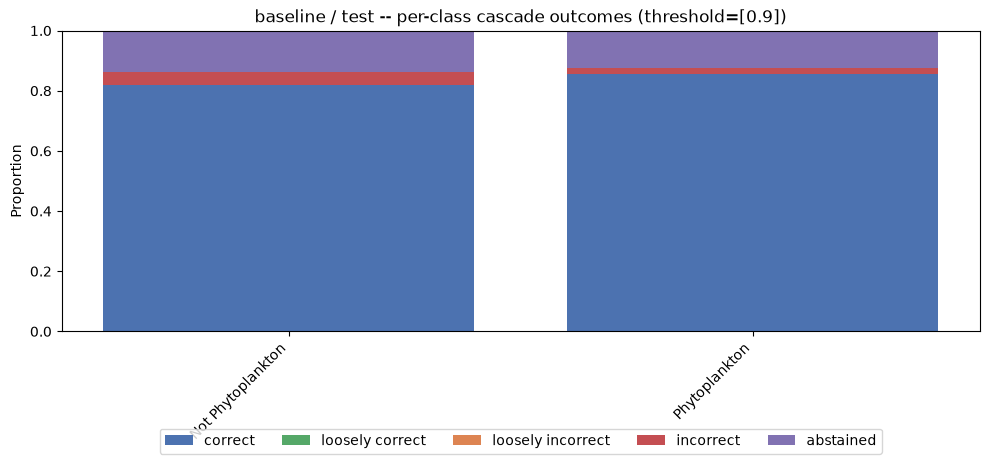

In [17]:
CONFIDENCE_THRESHOLDS = [0.9]   # one entry -- one hierarchy level

for (ckpt_name, tag), model in models.items():
    ds, loader = TARGETS[tag]
    props = per_class_outcomes(
        model, loader, CONFIDENCE_THRESHOLDS, ds.hierarchy,
        {v: k for k, v in ds.label_to_ids.items()}, device,
    )
    for cls, o in props.items():
        kept = 1 - o["abstained"]
        acc_kept = o["correct_lowest"] / kept if kept else float("nan")
        print(f"  {ckpt_name}/{tag}  {cls:<18} abstain={o['abstained']:.1%}  acc|kept={acc_kept:.1%}")
    plot_outcome_stacked_bar(
        props, f"{ckpt_name} / {tag} -- per-class cascade outcomes (threshold={CONFIDENCE_THRESHOLDS})",
    )
    plt.show()

# Attention & Grad-CAM

Swin-T self-attention and hierarchical Grad-CAM on one test sample. The binary
root-to-leaf path has a single edge, so Grad-CAM `weights` is `[1]` (the MNR
notebook uses length-3 lists for its 3-level path).

sample: Phytoplankton | 20250722_4x300um_Helen_Rep4_000002_p57_x751_y829.tif


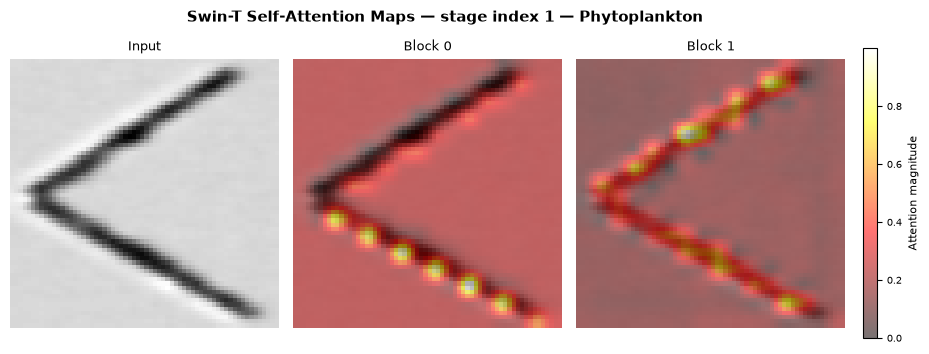

In [13]:
sample_idx = test_split[0]
sample_path = test_hier_dataset.image_paths[sample_idx]
label_name = id_to_name[test_hier_dataset.labels[sample_idx]]
print("sample:", label_name, "|", Path(sample_path).name)

img = Image.open(sample_path).convert("L")
img_tensor = transforms.Compose([
    transforms.Resize((RESOLUTION, RESOLUTION)),
    transforms.ToTensor(),
])(img).unsqueeze(0).repeat(1, 3, 1, 1)

eval_model = models.get(("baseline", "test")) or next(iter(models.values()))

fig = visualize_swin_attention(eval_model, img_tensor, stage=1, label=label_name,
                               show_input=True, overlay=True)

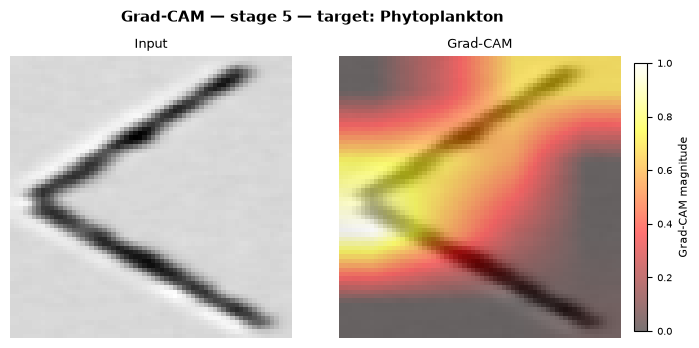

In [14]:
# Grad-CAM for the single phytoplankton-vs-not decision (weights=[1]).
fig = visualize_gradcam(eval_model, img_tensor, label_name, weights=[1],
                        stage=5, overlay=True, show_input=True)